![Banner](../images/09_03_banner_rs_rader.png)


# NISAR GUNW: Geocoded Unwrapped Interferogram

This notebook uses GeoLattice to inspect and process the NISAR Level-2 GUNW product for the coastal Bangladesh AOI.


## Overview

It reads the HH unwrapped phase, coherence, connected-component labels, and ionosphere-screen layers from the supplied HDF5 file. GUNW is already geocoded; the AOI is selected from its projected grid.


## Core concepts

### Learning objectives

1. Inspect GUNW identification metadata, wavelength from the center frequency, and the frequencyA layer inventory.
2. Select the coastal Bangladesh AOI window from the 80 m EPSG:32646 coordinate axes.
3. Read HH unwrapped phase, coherence, connected components, and the ionosphere screen in bounded HDF5 chunks.
4. Quality-mask and reference the phase with `nisar.process_unwrapped_phase`, using coherence and connected-component labels.
5. Convert the referenced phase to relative line-of-sight displacement with the product center frequency.
6. Inspect the ionosphere phase screen and its uncertainty without applying a correction whose sign is unverified.
7. Clip phase, displacement, and coherence to the AOI polygon and state why one interferogram is not absolute or vertical motion.

### Contents

1. Processing overview and limitations
2. Inspect product metadata and layers
3. Select the AOI and view it on satellite imagery
4. Read the AOI window in bounded chunks
5. Quality-mask and reference phase with GeoLattice
6. Inspect phase quality and ionosphere layers
7. Clip and map the AOI displacement
8. Optionally export AOI layers
9. Summary, exercises and references


## Processing overview and limitations

The scene contains an HH pair with a reference acquisition on 2026-09-22 and a secondary acquisition on 2026-10-04, a 12-day interval. The geocoded layers are on an 80 m EPSG:32646 grid. The workflow quality-masks unwrapped phase using coherence and connected-component labels, references phase to a selected stable area, and converts relative phase to line-of-sight (LOS) displacement using the product center frequency.

The reference area defines an arbitrary zero and must be stable; the default GeoLattice selection is only a provisional high-coherence reference within the largest valid component. For scientific results, provide a known stable reference polygon. A single interferogram does not provide absolute deformation or separate deformation from atmosphere, ionosphere, orbit errors, or decorrelation. The ionosphere screen and uncertainty are inspected but not subtracted because the layer metadata does not specify a correction sign convention. Review the matching product specification before applying any correction or assigning toward/away LOS signs.


**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Import libraries, set plotting defaults, and locate the NISAR GUNW HDF5 scene and AOI file on disk.

from pathlib import Path

import geopandas as gpd  # vector data (the AOI)
import h5py  # read NISAR HDF5 files
import leafmap  # interactive web maps
import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import rioxarray  # registers the .rio accessor
import xarray as xr  # labelled rasters

from geolattice import rsense as rs  # GeoLattice remote sensing
from geolattice.rsense.sar import nisar  # NISAR helpers

# 1. Use a slightly higher DPI than the matplotlib default so the phase, coherence, and
#    displacement panels plotted later in the notebook are crisp without being oversized.
plt.rcParams.update({"figure.dpi": 110})

# 2. Resolve the data directory so the notebook runs both from the repository root and from
#    its own folder: try the path relative to the repo root first, then fall back to a
#    directory next to the notebook itself.
DATA_RELATIVE = Path("Data/08_remote_sensing/08_03_radar/NISAR_bd")
if not DATA_RELATIVE.exists():  # when run from the repository root instead of this folder
    DATA_RELATIVE = Path("../../../../Data/08_remote_sensing/08_03_radar/NISAR_bd")  # use the path from the root
DATA_DIR = DATA_RELATIVE  # the data folder

# 3. Build the path to the GUNW product. The filename itself encodes the acquisition
#    metadata referenced throughout the notebook: track/frame numbers, the HH polarization,
#    and the reference (2026-09-22) and secondary (2026-10-04) zero-Doppler start/end times
#    that define the ~12-day interferometric pair.
SCENE = DATA_DIR / (
    "NISAR_L2_PR_GUNW_031_069_A_013_032_4000_SH_20260922T232058_"
    "20260922T232133_20261004T232058_20261004T232133_P05023_N_F_J_001.h5"
)
AOI_PATH = DATA_DIR / "AOI_coastal.geojson"  # the coastal AOI polygon

# 4. Fail fast with clear messages if the expected inputs are missing, rather than letting
#    later HDF5/GeoPandas calls raise cryptic errors deep in the workflow.
assert SCENE.is_file(), f"NISAR GUNW file not found: {SCENE.resolve()}"
assert AOI_PATH.is_file(), f"AOI GeoJSON not found: {AOI_PATH.resolve()}"  # stop if the AOI file is missing

# 5. Confirm which GeoLattice version and which input files this run is using.
print(f"GeoLattice remote sensing version: {rs.__version__}")
print(f"GUNW: {SCENE.name}")  # the GUNW file
print(f"AOI:  {AOI_PATH}")  # the AOI file

GeoLattice remote sensing version: 0.2.0.dev0
GUNW: NISAR_L2_PR_GUNW_031_069_A_013_032_4000_SH_20260922T232058_20260922T232133_20261004T232058_20261004T232133_P05023_N_F_J_001.h5
AOI:  data/NISAR_bd/AOI_coastal.geojson


## Inspect product metadata and layers

GeoLattice reads the product identification metadata and inventories the frequency-A grid without loading the multi-gigabyte HDF5 raster layers.


In [2]:
# Inspect product identification metadata and the frequency-A grid layout without loading the
# multi-gigabyte raster layers themselves.

# 1. read_identification parses the lightweight HDF5 identification group (mission, product
#    type/level/version, track/frame, orbit pass and look direction, and the reference/
#    secondary acquisition timestamps). inspect_hdf5 walks the frequency-A grid group and
#    returns shape/dtype/attrs for every dataset it contains, again without reading the data.
identification = nisar.read_identification(SCENE, "GUNW")
GRID = "/science/LSAR/GUNW/grids/frequencyA"  # HDF5 path of the frequency-A grid
GRID_INFO = nisar.inspect_hdf5(SCENE, GRID)  # list its datasets

# 2. Print only the identification fields relevant to this workflow: what the product is,
#    which track/frame/orbit geometry it covers, and the reference/secondary acquisition
#    times that define the interferometric pair and its ~12-day interval.
for key in (
    "missionId", "productType", "productLevel", "productVersion",
    "trackNumber", "frameNumber", "orbitPassDirection", "lookDirection",
    "referenceZeroDopplerStartTime", "secondaryZeroDopplerStartTime",
    "referenceZeroDopplerEndTime", "secondaryZeroDopplerEndTime",
):
    if key in identification:  # print only the fields that are present
        print(f"{key}: {identification[key]}")  # field name and value

# 3. Open the HDF5 file directly to pull a few scalar/array values that inspect_hdf5 does not
#    summarize: the map projection EPSG code, the radar center frequency (converted to the
#    wavelength needed later to turn phase into line-of-sight displacement), and the x/y
#    coordinate axes and pixel spacing of the geocoded grid.
with h5py.File(SCENE, "r") as f:
    grid = f[GRID]  # the frequency-A grid group
    epsg = int(grid["unwrappedInterferogram/HH/projection"][()])  # EPSG code of the map projection
    center_frequency_hz = float(grid["centerFrequency"][()])  # radar centre frequency (Hz)
    wavelength_m = 299_792_458.0 / center_frequency_hz  # wavelength = c / frequency
    x_axis = grid["unwrappedInterferogram/HH/xCoordinates"][:]  # x coordinate of every column
    y_axis = grid["unwrappedInterferogram/HH/yCoordinates"][:]  # y coordinate of every row
    x_spacing = float(grid["unwrappedInterferogram/HH/xCoordinateSpacing"][()])  # pixel spacing in x (m)
    # pixel spacing in y (m, negative: north-up)
    y_spacing = float(grid["unwrappedInterferogram/HH/yCoordinateSpacing"][()])
    print(f"Center frequency: {center_frequency_hz / 1e9:.4f} GHz")  # centre frequency
    print(f"Radar wavelength: {wavelength_m:.4f} m")  # wavelength
    print(f"Map grid: EPSG:{epsg}; spacing {x_spacing:g} m x {abs(y_spacing):g} m")  # CRS and pixel spacing

# 4. List shape, dtype, and units for the specific layers this notebook will read later
#    (unwrapped phase, coherence, connected-component labels, and the two ionosphere-screen
#    layers), confirming they exist and are sized as expected before committing to the
#    chunked HDF5 reads below.
[(path, info["shape"], info["dtype"], info["attrs"].get("units"))
 for path, info in GRID_INFO.items()
 if any(name in path for name in (
     "unwrappedPhase", "coherenceMagnitude", "connectedComponents",
     "ionospherePhaseScreen", "ionospherePhaseScreenUncertainty",
 ))]

missionId: NISAR
productType: GUNW
productLevel: L2
productVersion: 1.0.11
trackNumber: 69
frameNumber: 13
orbitPassDirection: Ascending
lookDirection: Left
referenceZeroDopplerStartTime: 2026-09-22T23:20:58.000000000
secondaryZeroDopplerStartTime: 2026-10-04T23:20:58.000000000
referenceZeroDopplerEndTime: 2026-09-22T23:21:33.999342105
secondaryZeroDopplerEndTime: 2026-10-04T23:21:33.999342105
Center frequency: 1.2390 GHz
Radar wavelength: 0.2420 m
Map grid: EPSG:32646; spacing 80 m x 80 m


[('/science/LSAR/GUNW/grids/frequencyA/unwrappedInterferogram/HH/coherenceMagnitude',
  (4194, 4275),
  'float32',
  '1'),
 ('/science/LSAR/GUNW/grids/frequencyA/unwrappedInterferogram/HH/connectedComponents',
  (4194, 4275),
  'uint16',
  '1'),
 ('/science/LSAR/GUNW/grids/frequencyA/unwrappedInterferogram/HH/ionospherePhaseScreen',
  (4194, 4275),
  'float32',
  'radians'),
 ('/science/LSAR/GUNW/grids/frequencyA/unwrappedInterferogram/HH/ionospherePhaseScreenUncertainty',
  (4194, 4275),
  'float32',
  'radians'),
 ('/science/LSAR/GUNW/grids/frequencyA/unwrappedInterferogram/HH/unwrappedPhase',
  (4194, 4275),
  'float32',
  'radians'),
 ('/science/LSAR/GUNW/grids/frequencyA/wrappedInterferogram/HH/coherenceMagnitude',
  (16776, 17100),
  'float32',
  '1')]

## Select the AOI and view it on satellite imagery

The AOI is transformed to the GUNW map CRS, and its projected bounds select the smallest enclosing row/column window. Leafmap shows the AOI over satellite imagery as geographic context; raster selection is performed using GUNW coordinates.


In [3]:
# Load the AOI polygon, project it into the GUNW map grid to find the row/column window to
# read, and display the AOI over satellite imagery for geographic context.

# 1. Load the AOI GeoJSON and make sure it has features and a defined CRS. GeoJSON is
#    normally WGS84 (EPSG:4326) by convention, so assume that if no CRS is declared.
aoi = gpd.read_file(AOI_PATH)
if aoi.empty:  # the AOI file has no polygon
    raise ValueError(f"AOI contains no features: {AOI_PATH}")  # stop with a clear message
if aoi.crs is None:  # assume WGS 84 when the file has no CRS
    aoi = aoi.set_crs("EPSG:4326")  # set it

# 2. Keep two reprojected copies: aoi_ll in geographic coordinates for the Leafmap basemap
#    display, and aoi_grid in the GUNW product's own map projection (read from the HDF5
#    metadata above) for selecting pixels on the native grid.
aoi_ll = aoi.to_crs("EPSG:4326")
aoi_grid = aoi.to_crs(f"EPSG:{epsg}")  # the AOI in the grid's projection
min_x, min_y, max_x, max_y = aoi_grid.total_bounds  # its bounding box

# 3. Find the smallest contiguous block of rows/columns on the GUNW coordinate axes that
#    encloses the AOI's projected bounding box. Working in grid-native coordinates (rather
#    than resampling) lets step 3 below read only this window from the multi-gigabyte HDF5
#    file instead of the whole scene.
row_indices = np.flatnonzero((y_axis >= min_y) & (y_axis <= max_y))
column_indices = np.flatnonzero((x_axis >= min_x) & (x_axis <= max_x))  # columns inside the AOI
if row_indices.size == 0 or column_indices.size == 0:  # no overlap
    raise ValueError("The AOI does not overlap the GUNW map grid")  # stop with a clear message
row_start, row_stop = int(row_indices[0]), int(row_indices[-1] + 1)  # first and last row (+1)
column_start, column_stop = int(column_indices[0]), int(column_indices[-1] + 1)  # first and last column (+1)
window = (row_start, row_stop, column_start, column_stop)  # the window
# AOI bounds in the grid CRS
print(f"AOI bounds in EPSG:{epsg}: {min_x:.1f}, {min_y:.1f}, {max_x:.1f}, {max_y:.1f}")
# the grid window
print(f"GUNW window: rows {row_start:,}:{row_stop:,}, columns {column_start:,}:{column_stop:,}")
print(f"Window size: {row_stop-row_start:,} x {column_stop-column_start:,} native pixels")  # its size

# 4. Build a Leafmap satellite-imagery view centered on the AOI, purely as geographic
#    context for the reader -- the actual raster selection above already used the projected
#    GUNW coordinates, not this map.
west, south, east, north = aoi_ll.total_bounds
center = ((south + north) / 2, (west + east) / 2)  # map centre (lat, lon)
aoi_map = leafmap.Map(center=center, zoom=8, height="600px")  # an interactive map
aoi_map.add_basemap("Esri.WorldImagery")  # satellite basemap
aoi_map.add_gdf(  # add the AOI polygon
    aoi_ll,
    layer_name="Coastal AOI",
    style={"color": "#ff3b30", "weight": 3, "fillColor": "#ff3b30", "fillOpacity": 0.12},
    hover_style={"color": "#ffff00", "weight": 4, "fillOpacity": 0.2},
    zoom_to_layer=False,
)
aoi_map.add_layer_control()  # layer switcher
aoi_map  # show the map

AOI bounds in EPSG:32646: 219364.0, 2420523.2, 351768.2, 2532569.9
GUNW window: rows 1,940:3,340, columns 1,302:2,957
Window size: 1,400 x 1,655 native pixels


Map(center=[np.float64(22.38019), np.float64(90.91958)], controls=(ZoomControl(options=['position', 'zoom_in_t…

## Read the AOI window in bounded chunks

The product's nested layer groups contain their own coordinate axes and projection. GeoLattice `read_l2` supports these nested geocoded layers; this notebook uses HDF5 window reads to avoid loading full-scene arrays. The connected-component fill value is converted to zero so GeoLattice excludes it along with unlabeled pixels.


In [4]:
# Read the AOI window for every needed layer directly from the HDF5 file, in row chunks, so
# the full-scene arrays are never loaded into memory.

# 1. Map each GeoLattice-friendly name used in this notebook to the actual HDF5 dataset name under
#    the HH unwrappedInterferogram group: the unwrapped phase itself, its supporting
#    coherence and connected-component quality layers, and the ionosphere phase screen plus
#    its uncertainty (inspected later as diagnostics only).
LAYERS = {
    "phase": "unwrappedPhase",
    "coherence": "coherenceMagnitude",
    "components": "connectedComponents",
    "ionosphere": "ionospherePhaseScreen",
    "ionosphere_uncertainty": "ionospherePhaseScreenUncertainty",
}

# 2. Read in fixed-size row chunks rather than one HDF5 slice covering the whole AOI window,
#    bounding peak memory use regardless of how large the AOI is. Pre-allocate NaN-filled
#    output arrays for every layer so any pixels not covered end up as NaN rather than zero.
CHUNK_ROWS = 128
row0, row1, col0, col1 = window  # window bounds
window_shape = (row1 - row0, col1 - col0)  # window size
arrays = {name: np.full(window_shape, np.nan, dtype="float32") for name in LAYERS}  # one output array per layer

# 3. Walk the AOI window row-chunk by row-chunk, reading every layer for that chunk in one
#    pass. The connected-component fill value (the sentinel used for pixels that belong to no
#    valid component) is converted to 0 so that, downstream, GeoLattice can treat "no component"
#    and "filled/invalid" consistently when it excludes unlabeled pixels.
with h5py.File(SCENE, "r") as f:
    layer_group = f[f"{GRID}/unwrappedInterferogram/HH"]  # the HH unwrapped-interferogram group
    # fill value of the connected-component labels
    component_fill = layer_group["connectedComponents"].attrs.get("_FillValue", 65535)
    for local_start in range(0, window_shape[0], CHUNK_ROWS):  # read the window in chunks of rows
        count = min(CHUNK_ROWS, window_shape[0] - local_start)  # rows in this chunk
        rows = slice(row0 + local_start, row0 + local_start + count)  # source rows
        cols = slice(col0, col1)  # source columns
        target = slice(local_start, local_start + count)  # target rows in the output arrays
        for name, dataset_name in LAYERS.items():  # every layer
            values = layer_group[dataset_name][rows, cols]  # read the chunk
            if name == "components":  # component labels:
                values = values.astype("float32")  # as floats
                values[values == component_fill] = 0  # fill value -> 0 (no component)
            arrays[name][target] = values  # store the chunk

# 4. Wrap each loaded array as a georeferenced xarray.DataArray on the AOI's slice of the
#    native x/y coordinate axes, so downstream GeoLattice processing and rioxarray-based clipping
#    (steps 4-6 below) can operate on them directly.
out_x = x_axis[col0:col1]
out_y = y_axis[row0:row1]  # y coordinates of the window
coords = {"y": out_y, "x": out_x}  # coordinates of the output grid
# unwrapped phase as a DataArray
phase = xr.DataArray(arrays["phase"], dims=("y", "x"), coords=coords, name="unwrapped_phase")
coherence = xr.DataArray(arrays["coherence"], dims=("y", "x"), coords=coords, name="coherence")  # coherence
# connected-component labels
components = xr.DataArray(arrays["components"], dims=("y", "x"), coords=coords, name="connected_components")
# ionosphere phase screen
ionosphere = xr.DataArray(arrays["ionosphere"], dims=("y", "x"), coords=coords, name="ionosphere_phase_screen")
ionosphere_uncertainty = xr.DataArray(  # its uncertainty
    arrays["ionosphere_uncertainty"], dims=("y", "x"), coords=coords,
    name="ionosphere_phase_screen_uncertainty",
)

# 5. Sanity-check the loaded window: how much of the AOI has finite (non-NaN) phase and
#    coherence data, and which connected-component labels are actually present.
print(f"Loaded AOI window: {phase.shape[0]:,} x {phase.shape[1]:,} pixels")
print(f"Finite phase fraction: {np.isfinite(phase).mean():.1%}")  # finite phase share
print(f"Finite coherence fraction: {np.isfinite(coherence).mean():.1%}")  # finite coherence share
# component labels present
print(f"Connected-component labels: {np.unique(components.values[np.isfinite(components)])}")

Loaded AOI window: 1,400 x 1,655 pixels
Finite phase fraction: 100.0%
Finite coherence fraction: 100.0%
Connected-component labels: [0. 1. 2.]


## Quality-mask and reference phase with GeoLattice

GeoLattice removes pixels below the coherence threshold and pixels without a connected-component label. By default, `process_unwrapped_phase` uses the largest valid component and its highest-coherence quartile to estimate a phase reference. This is a reproducible demonstration, not proof that the selected pixels are geologically stable. Set `REFERENCE_AOI_PATH` to a known stable reference polygon to override the automatic selection. Ionosphere correction remains disabled until its sign convention is verified.


In [5]:
# Quality-mask the unwrapped phase, reference it to a stable area, and convert it to relative
# line-of-sight (LOS) displacement using GeoLattice.

# 1. Pixels with coherence below this threshold are excluded as unreliable. REFERENCE_AOI_PATH
#    stays None by default, so GeoLattice falls back to its own automatic reference-pixel
#    selection; set it to a known stable polygon's path for a scientifically defensible
#    reference instead of the provisional one GeoLattice picks.
MIN_COHERENCE = 0.30
REFERENCE_AOI_PATH = None  # Optionally set a path to a stable reference polygon
reference_mask = None  # no reference area by default

# 2. Only runs when a reference polygon path is supplied: load it, reproject it into the GUNW
#    grid CRS, and rasterize it onto the AOI window's pixel grid (geometry_mask with
#    invert=True marks pixels inside the polygon as True) so GeoLattice can average the phase
#    there as the manual zero reference instead of guessing one.
if REFERENCE_AOI_PATH is not None:
    import rasterio  # raster tools
    from rasterio.features import geometry_mask  # rasterise a polygon into a mask
    from rasterio.transform import from_origin  # transform of a north-up grid

    reference_aoi = gpd.read_file(REFERENCE_AOI_PATH)  # the reference area polygon
    if reference_aoi.empty:  # empty file
        # stop with a clear message
        raise ValueError(f"Reference AOI contains no features: {REFERENCE_AOI_PATH}")
    if reference_aoi.crs is None:  # the file has no CRS
        # stop with a clear message
        raise ValueError("Reference AOI must declare its coordinate reference system")
    reference_aoi = reference_aoi.to_crs(f"EPSG:{epsg}")  # into the grid CRS
    # transform of the output grid
    transform = from_origin(out_x[0] - x_spacing / 2, out_y[0] - abs(y_spacing) / 2,
                            abs(x_spacing), abs(y_spacing))
    reference_mask = geometry_mask(  # True outside the reference polygon
        reference_aoi.geometry, out_shape=phase.shape, transform=transform, invert=True
    )

# 3. Hand the phase, coherence, and connected-component layers to GeoLattice. It excludes pixels
#    below min_coherence and pixels with no valid component label, picks (or uses the
#    supplied) reference_mask to zero the phase at a stable area, and converts the referenced
#    phase to LOS displacement using the radar wavelength computed earlier from the center
#    frequency (the standard InSAR relation displacement = phase * wavelength / (4*pi)).
gunw = nisar.process_unwrapped_phase(
    phase,
    wavelength=wavelength_m,
    coherence=coherence,
    min_coherence=MIN_COHERENCE,
    connected_components=components,
    reference_mask=reference_mask,
)
los_displacement = gunw["los_displacement"].rename("relative_los_displacement")  # relative LOS displacement (m)
valid = gunw["valid"]  # quality mask

# 4. Report the reference phase GeoLattice used, the fraction of pixels that survived quality
#    masking, and the displacement range (2nd-98th percentile, to avoid outliers) -- all as
#    relative LOS displacement with respect to the chosen reference, not absolute motion.
print(f"GeoLattice phase reference: {gunw.attrs['reference_phase_rad']:.3f} rad")
print(f"Valid pixels after quality masking: {valid.values.mean():.1%}")  # valid share
print(f"LOS displacement range: {np.nanpercentile(los_displacement, 2):.3f} to "  # displacement range
      f"{np.nanpercentile(los_displacement, 98):.3f} m (2nd-98th percentile)")

GeoLattice phase reference: 0.181 rad
Valid pixels after quality masking: 7.9%
LOS displacement range: -0.064 to 0.169 m (2nd-98th percentile)


The displacement is relative to the selected reference phase, not absolute ground motion. The displayed LOS values inherit the phase-sign convention used by GeoLattice; verify the product documentation before interpreting positive values as motion toward or away from the sensor. Do not treat low-coherence or disconnected components as reliable deformation.


## Inspect phase quality and ionosphere layers

The ionosphere phase screen and its uncertainty are shown as diagnostics only. Their presence does not establish whether to add or subtract the screen from this unwrapped phase; the correction sign and supported use must be confirmed from the matching GUNW product specification.


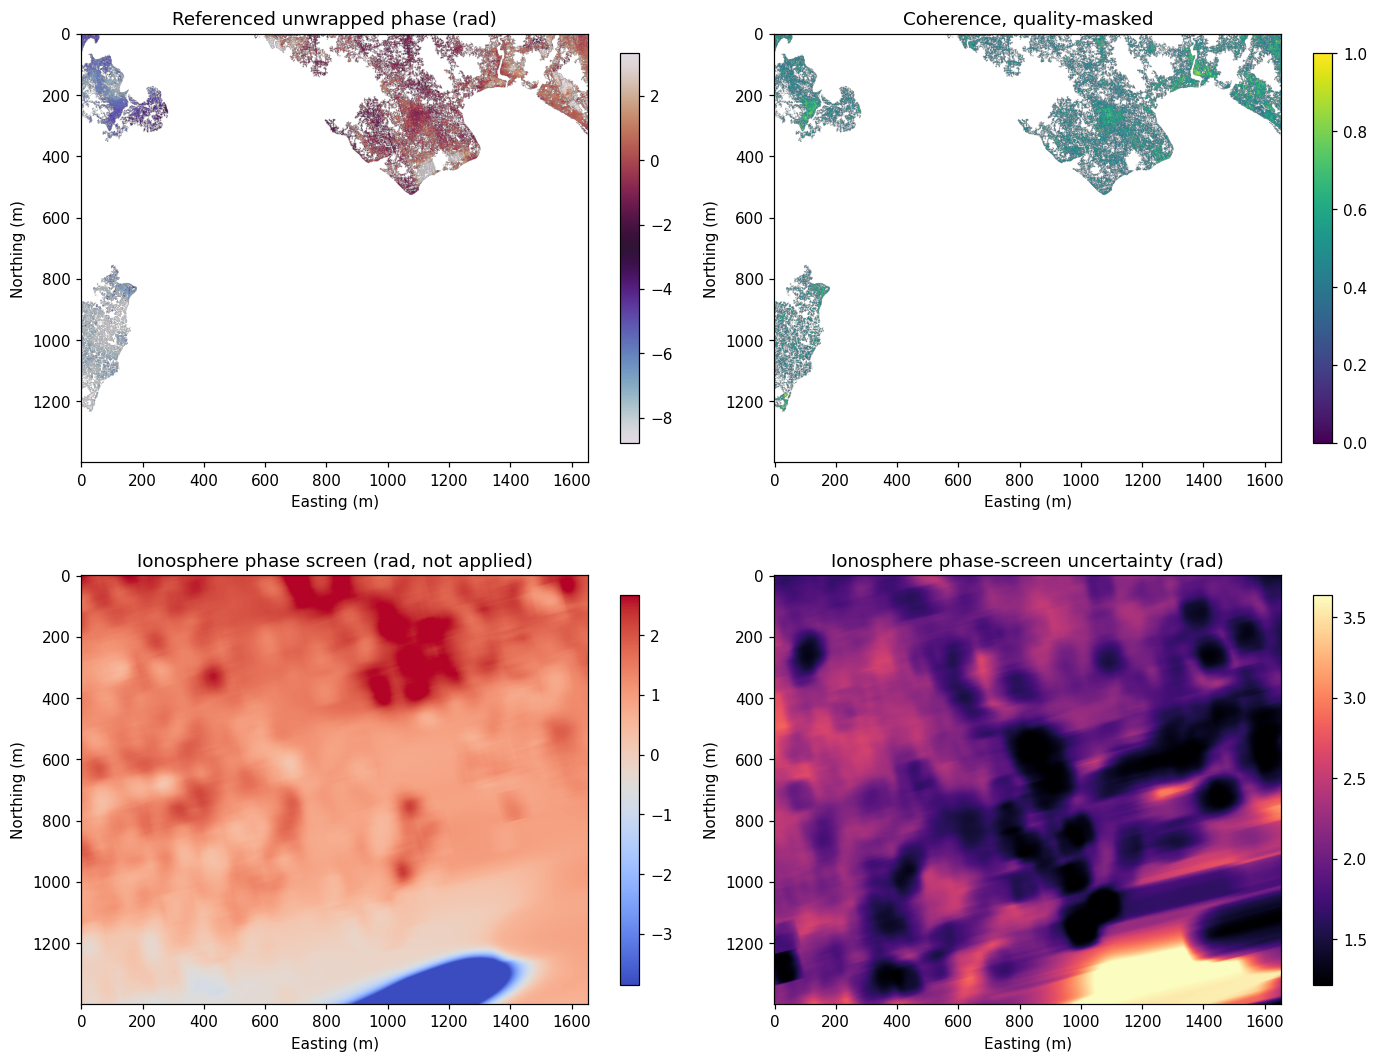

In [6]:
# Plot a 2x2 panel of phase-quality and ionosphere diagnostics over the AOI window.

# 1. Pair each layer with its display title, colormap, and color limits: the referenced
#    phase and the two ionosphere layers use robust 2nd-98th-percentile stretching (limits
#    left as None), while coherence is fixed to its natural 0-1 range. coherence.where(valid)
#    shows coherence only where GeoLattice kept the pixel after quality masking.
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
panels = (  # the panels: image, title, colour map and limits
    (axes[0, 0], gunw["unwrapped_phase"], "Referenced unwrapped phase (rad)", "twilight", None),
    (axes[0, 1], coherence.where(valid), "Coherence, quality-masked", "viridis", (0, 1)),
    (axes[1, 0], ionosphere, "Ionosphere phase screen (rad, not applied)", "coolwarm", None),
    (axes[1, 1], ionosphere_uncertainty, "Ionosphere phase-screen uncertainty (rad)", "magma", None),
)

# 2. Draw each panel: fall back to a robust percentile stretch when explicit limits were not
#    given, render the array, and attach a colorbar. The ionosphere panels are labeled
#    "not applied" as a reminder that this screen is shown for inspection only and has not
#    been subtracted from the phase, since its correction sign convention is unverified.
for ax, image, title, cmap, limits in panels:
    # fixed limits, or a 2-98 % stretch
    vmin, vmax = limits if limits is not None else np.nanpercentile(image.values, [2, 98])
    artist = ax.imshow(image, cmap=cmap, vmin=vmin, vmax=vmax, origin="upper")  # show the image
    ax.set(title=title, xlabel="Easting (m)", ylabel="Northing (m)")  # title and axis labels
    plt.colorbar(artist, ax=ax, shrink=0.78)  # colour bar
plt.tight_layout()  # arrange
plt.show()  # draw

## Clip and map the AOI displacement

The raster window includes the AOI bounding rectangle; rioxarray clips the outputs to the exact GeoJSON polygon. The source grid remains at its native 80 m spacing.


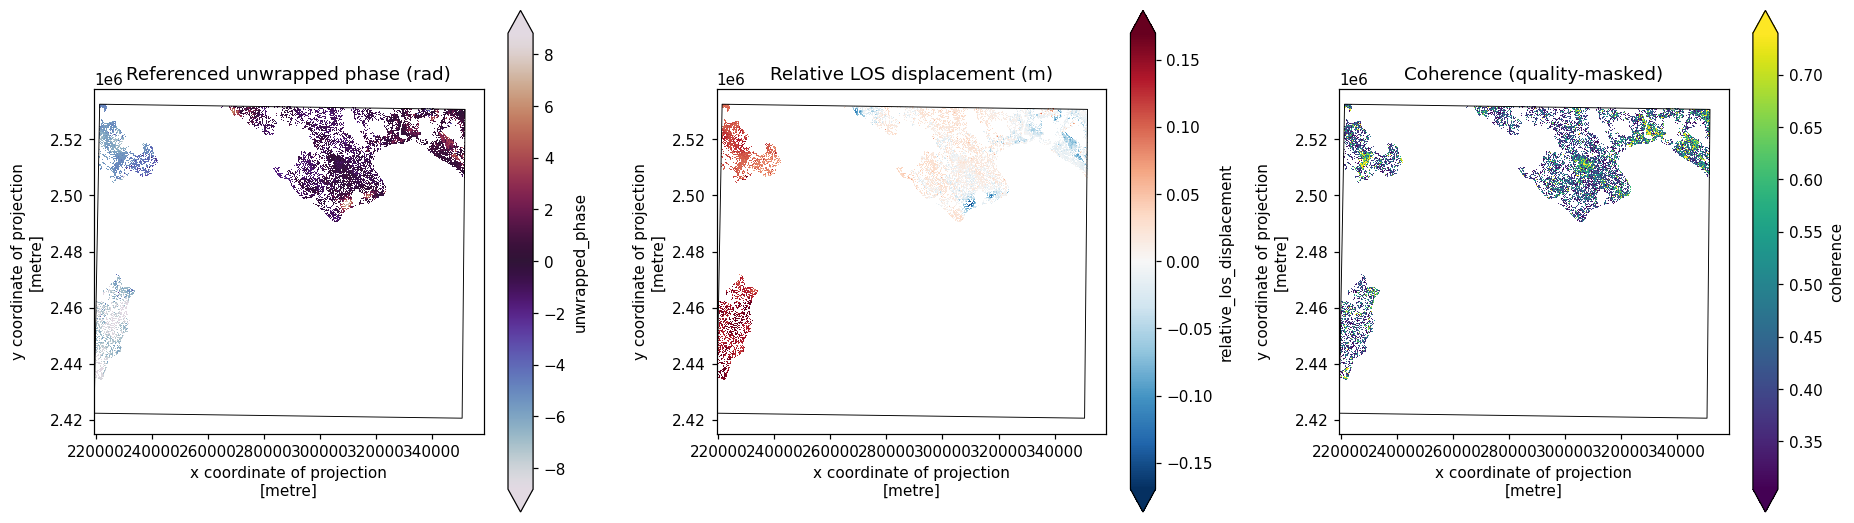

AOI result grid: 1,400 rows x 1,655 columns
CRS: EPSG:32646; source pixel spacing: 80 m


In [7]:
# Clip the windowed rasters to the exact AOI polygon (not just its bounding box) and map the
# referenced phase, LOS displacement, and coherence side by side.

# 1. Attach the GUNW grid CRS to an xarray.DataArray via rioxarray, then clip it to the AOI's
#    actual polygon geometry rather than the rectangular row/column window read earlier.
#    all_touched=True keeps any pixel the polygon boundary passes through, and drop=True
#    discards pixels outside the clipped extent instead of just masking them.
def georeference_and_clip(image):
    # tell rioxarray which dimensions are x and y, and attach the CRS
    return image.rio.set_spatial_dims(x_dim="x", y_dim="y").rio.write_crs(
        f"EPSG:{epsg}"
    ).rio.clip(aoi_grid.geometry, aoi_grid.crs, drop=True, all_touched=True)

# 2. Apply the clip to the referenced phase, LOS displacement, quality-masked coherence, and
#    quality-masked connected components, all on the native 80 m grid.
phase_aoi = georeference_and_clip(gunw["unwrapped_phase"])
los_aoi = georeference_and_clip(los_displacement)  # LOS displacement, clipped to the AOI
coherence_aoi = georeference_and_clip(coherence.where(valid))  # coherence of the valid pixels, clipped
components_aoi = georeference_and_clip(components.where(valid))  # component labels of the valid pixels, clipped

# 3. Map the three clipped layers side by side with a robust percentile color stretch, and
#    overlay the AOI polygon boundary so the clip extent is visible on each panel.
fig, axes = plt.subplots(1, 3, figsize=(17, 6))
for ax, image, title, cmap in (  # the panels with their titles and colour maps
    (axes[0], phase_aoi, "Referenced unwrapped phase (rad)", "twilight"),
    (axes[1], los_aoi, "Relative LOS displacement (m)", "RdBu_r"),
    (axes[2], coherence_aoi, "Coherence (quality-masked)", "viridis"),
):
    image.plot.imshow(ax=ax, cmap=cmap, robust=True, cbar_kwargs={"shrink": 0.8})  # show with a robust stretch
    aoi_grid.boundary.plot(ax=ax, color="black", linewidth=0.6)  # AOI outline
    ax.set_title(title)  # title
    ax.set_aspect("equal")  # equal scale
plt.tight_layout()  # arrange
plt.show()  # draw

# 4. Report the final clipped grid size, CRS, and native pixel spacing for reference.
print(f"AOI result grid: {los_aoi.sizes['y']:,} rows x {los_aoi.sizes['x']:,} columns")
print(f"CRS: {los_aoi.rio.crs}; source pixel spacing: {abs(x_spacing):g} m")  # CRS and pixel spacing

## Optionally export AOI layers

Exports are disabled by default. The displacement GeoTIFF contains relative LOS values and should be accompanied by the reference choice, coherence threshold, phase convention, and product metadata when shared.


In [9]:
# Optionally export the clipped AOI layers to GeoTIFFs; disabled by default.

# 1. Export is gated behind this flag so running the notebook end-to-end does not silently
#    write files. Flip to True to write the referenced phase, relative LOS displacement, and
#    quality-masked coherence as LZW-compressed GeoTIFFs under the data directory.
WRITE_OUTPUTS = False
if WRITE_OUTPUTS:  # only when output writing is switched on
    output_dir = DATA_DIR / "gunw_aoi_outputs"  # output folder
    output_dir.mkdir(parents=True, exist_ok=True)  # create it
    # save the referenced phase
    phase_aoi.rio.to_raster(output_dir / "NISAR_GUNW_HH_referenced_phase_rad.tif", compress="LZW")
    # save the LOS displacement
    los_aoi.rio.to_raster(output_dir / "NISAR_GUNW_HH_relative_los_displacement_m.tif", compress="LZW")
    # save the coherence
    coherence_aoi.rio.to_raster(output_dir / "NISAR_GUNW_HH_coherence.tif", compress="LZW")
    print(f"Wrote AOI layers to {output_dir.resolve()}")  # where the files were written

## Summary, exercises and references

**Summary**

- The NISAR GUNW HH product contains a geocoded unwrapped interferogram for acquisitions 12 days apart, with the supplied AOI selected from its EPSG:32646 map grid.
- The phase, coherence, connected-component, and ionosphere layers were read from the AOI window in bounded HDF5 chunks.
- GeoLattice quality-masked phase using coherence and connected-component labels, referenced it to a stable-area estimate, and converted it to relative LOS displacement using the product center frequency.
- The ionosphere screen was inspected but not applied because its correction sign convention was not established from the layer metadata.
- The reference area's stability, phase sign, atmospheric/ionospheric effects, and product version must be checked before interpreting displacement quantitatively.

**Conclusion**

This notebook demonstrates a memory-bounded GeoLattice workflow for examining NISAR GUNW over coastal Bangladesh. The product is already geocoded, so map-coordinate axes are used to read only the AOI window. Phase-to-displacement conversion yields relative LOS displacement, not absolute or vertical motion. For defensible deformation analysis, select a documented stable reference, validate the product's phase convention and ionosphere correction, account for atmospheric and orbital errors, and combine independent interferograms or time-series methods where appropriate.

**Additional resources**

- [NASA NISAR mission data and products](https://nisar.jpl.nasa.gov/data/)
- [ASF DAAC NISAR dataset information](https://asf.alaska.edu/datasets/daac/nisar/)
- [NISAR product specification documentation](https://nisar.jpl.nasa.gov/data/documents/)
- [ISCE3 processing framework](https://github.com/isce-framework/isce3)
- [GeoLattice user guide](https://github.com/zia207/GeoLattice/blob/main/docs/USER_GUIDE.md)
- [GeoLattice NISAR readers and phase-processing utilities](https://github.com/zia207/GeoLattice/blob/main/src/rsense/sar/nisar.py)

Leafmap is required for the satellite basemap and is available through the optional `geolattice[rsense-viz]` dependencies. Confirm product version, layer units, phase convention, connected-component validity, and stable-reference selection before quantitative use.
